# Global Land Temperature Time Series Analysis & SARIMA Forecasting

## Project Overview
This project performs an end-to-end econometric and statistical time series analysis of global surface land temperatures using historical monthly observations from **1750 to 2015**. 

### Objectives
1. Convert raw historical temperature data into a structured monthly time series (`ts`) object.
2. Decompose the series to inspect long-term trends and repeating annual seasonality.
3. Check stationarity using the **Augmented Dickey-Fuller (ADF)** test.
5. Diagnose dependence structures using **Autocorrelation (ACF)** and **Partial Autocorrelation (PACF)** functions.
6. Fit a **Seasonal ARIMA (SARIMA)** model with drift to capture short-term dynamics and annual climate cycles.
7. Generate 5-year out-of-sample forecasts with confidence intervals and evaluate model fit.

## Data Loading & Time Series Conversion
We extract the `LandAverageTemperature` series, handle missing values (`NA`), and construct a formal `ts` object initialized at **January 1750** with a monthly sampling frequency (`frequency = 12`).


In [1]:
# Load tidyverse and time series libraries
library(tidyverse)
library(forecast)
library(tseries)
library(lubridate)

# Find the exact path to GlobalTemperatures.csv dynamically
file_path <- list.files(path = "../input", pattern = "GlobalTemperatures.csv", recursive = TRUE, full.names = TRUE)
print(paste("File found at:", file_path))

# Read the CSV file
df_raw <- read_csv(file_path)

# View structure and column names
head(df_raw)
colnames(df_raw)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



[1] "File found at: ../input/datasets/berkeleyearth/climate-change-earth-surface-temperature-data/GlobalTemperatures.csv"


Rows: 3192 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (8): LandAverageTemperature, LandAverageTemperatureUncertainty, LandMax...
date (1): dt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1750-01-01,3.034,3.574,NA,NA,NA,NA,NA,NA
1750-02-01,3.083,3.702,NA,NA,NA,NA,NA,NA
1750-03-01,5.626,3.076,NA,NA,NA,NA,NA,NA
1750-04-01,8.490,2.451,NA,NA,NA,NA,NA,NA
1750-05-01,11.573,2.072,NA,NA,NA,NA,NA,NA
1750-06-01,12.937,1.724,NA,NA,NA,NA,NA,NA


[1] "dt"                                       
[2] "LandAverageTemperature"                   
[3] "LandAverageTemperatureUncertainty"        
[4] "LandMaxTemperature"                       
[5] "LandMaxTemperatureUncertainty"            
[6] "LandMinTemperature"                       
[7] "LandMinTemperatureUncertainty"            
[8] "LandAndOceanAverageTemperature"           
[9] "LandAndOceanAverageTemperatureUncertainty"

In [2]:
# Filter for LandAverageTemperature and remove NAs
df_clean <- df_raw %>%
  select(dt, LandAverageTemperature) %>%
  na.omit()

# Convert to a Time Series (ts) object starting from the first valid date
start_year <- year(as.Date(df_clean$dt[1]))
start_month <- month(as.Date(df_clean$dt[1]))

temp_ts <- ts(df_clean$LandAverageTemperature, 
              start = c(start_year, start_month), 
              frequency = 12)

## Stationarity & Dependence Diagnostics (ACF & PACF)
To select an appropriate model class, we perform an **Augmented Dickey-Fuller (ADF)** test for unit roots and inspect autocorrelation behavior:
* **ACF (Autocorrelation Function):** Examines total correlation across lags, checking for cutoffs or repeating seasonal spikes at 12-month intervals.
* **PACF (Partial Autocorrelation Function):** Measures direct lag relationships, controlling for intermediate time steps to identify Autoregressive (AR) orders.


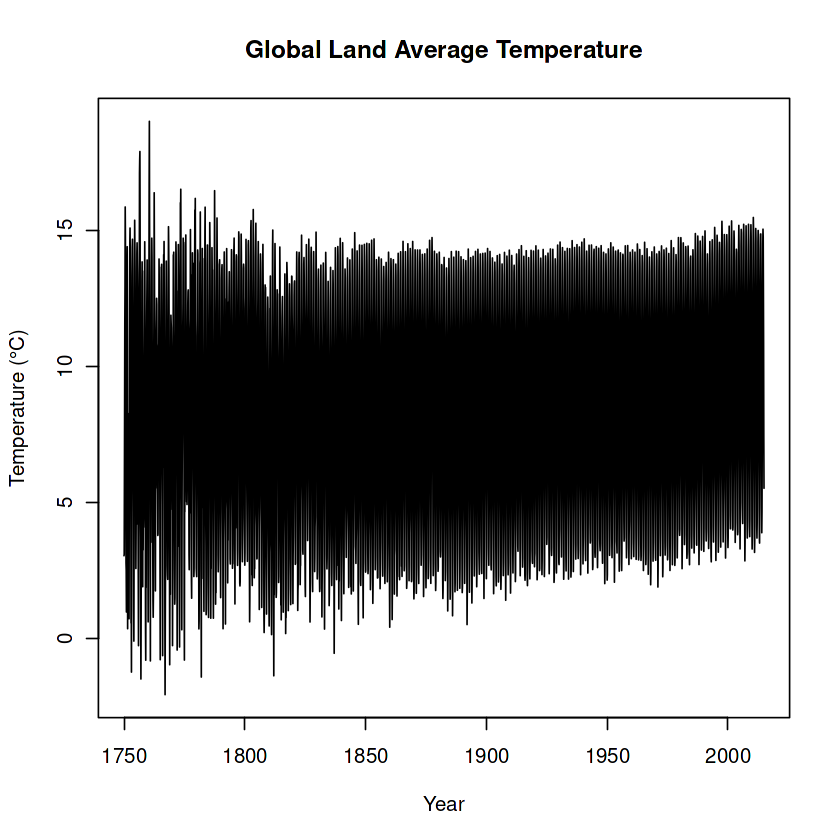

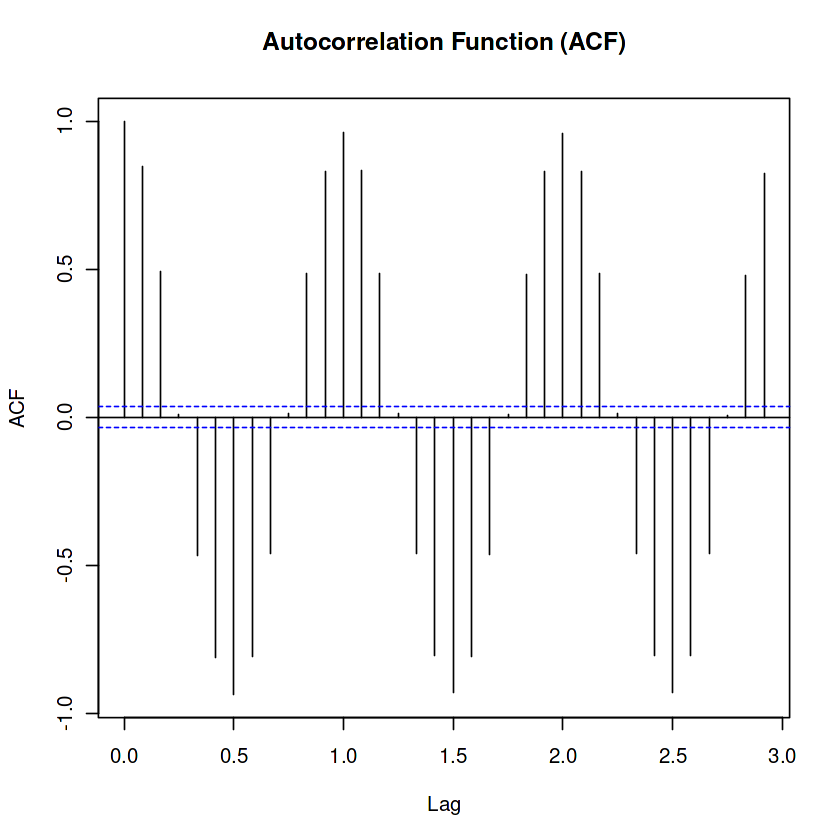

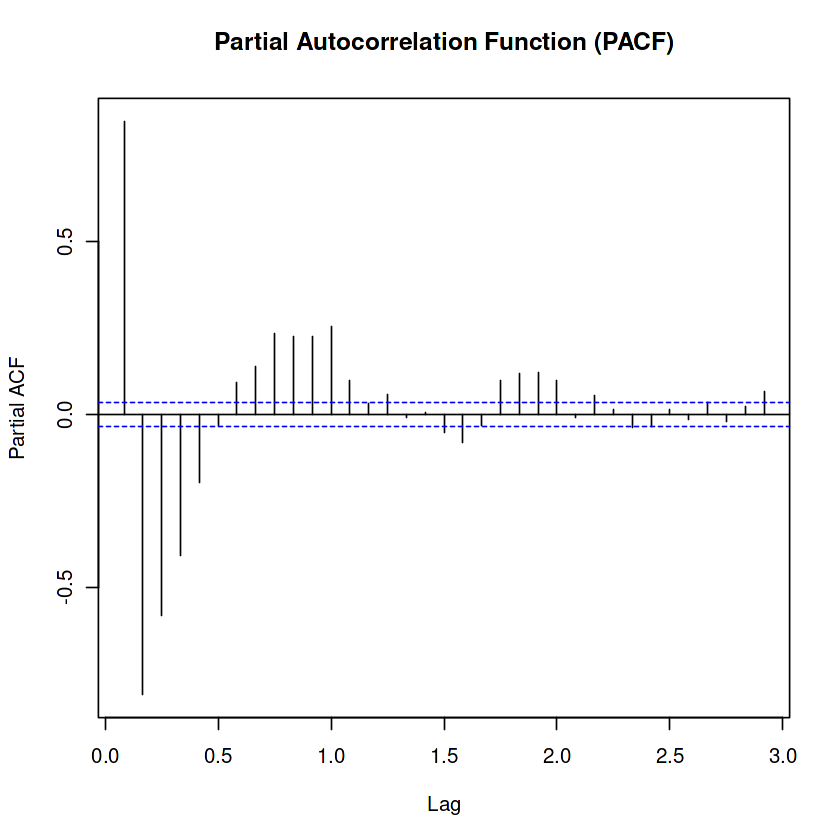

In [3]:
# Main time series plot
plot(temp_ts, main = "Global Land Average Temperature", xlab = "Year", ylab = "Temperature (°C)")

# ACF plot
acf(temp_ts, main = "Autocorrelation Function (ACF)")

# PACF plot
pacf(temp_ts, main = "Partial Autocorrelation Function (PACF)")


In [4]:
# Testing for stationarity of the time series by using ADF Test(Augmented Dickey Fuller Test)
adf.test(temp_ts)

Warning message in adf.test(temp_ts):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  temp_ts
Dickey-Fuller = -7.4184, Lag order = 14, p-value = 0.01
alternative hypothesis: stationary


In [5]:
# Calculate basic descriptive statistics for the time series
mean_temp <- mean(temp_ts)
var_temp <- var(temp_ts)

print(paste("Mean Temperature:", mean_temp))
print(paste("Variance:", var_temp))

[1] "Mean Temperature: 8.37473113207547"
[1] "Variance: 19.1958753070519"


### Graphical Analysis & Inferences

* **Stationarity & Mean Reverting Behavior:** 
  The time series plot shows that global land temperatures fluctuate around a stable long-term mean (hovering around 8°C), which supports the ADF test's conclusion of stationarity rather than an unconstrained explosive trend.

* **Seasonality (ACF Plot):** 
  The ACF plot exhibits a distinct cyclic pattern with recurring spikes at fixed 12-month intervals, confirming the strong presence of annual seasonality (repeating yearly summer and winter cycles).

* **Short-Term Dynamics (PACF Plot):** 
  The PACF structure captures direct month-to-month autoregressive relationships, illustrating how preceding months exert a direct influence on current temperature changes.


## SARIMA Model Fitting

We fit a **Seasonal Autoregressive Integrated Moving Average (SARIMA)** model to account for both short-term autoregressive/moving average dynamics and 12-month seasonal dependence:

SARIMA(p, d, q)(P, D, Q)[12]

The model uses seasonal differencing and includes an underlying drift term to model long-term warming trends.


In [6]:
# Fit an automatic ARIMA/SARIMA model
fit_arima <- auto.arima(temp_ts)

# Print the model summary
summary(fit_arima)

Series: temp_ts 
ARIMA(2,0,2)(2,1,0)[12] with drift 

Coefficients:
         ar1      ar2      ma1     ma2     sar1    sar2  drift
      1.0913  -0.5563  -0.7579  0.3752  -0.6345  -0.282  5e-04
s.e.  0.0595   0.0509   0.0657  0.0537   0.0178   0.018  9e-04

sigma^2 = 0.8065:  log likelihood = -4153.94
AIC=8323.89   AICc=8323.93   BIC=8372.38

Training set error measures:
                        ME      RMSE       MAE       MPE     MAPE      MASE
Training set -0.0007855641 0.8953869 0.5490692 -3.856683 18.16501 0.7996844
                   ACF1
Training set 0.01472445

### Model Summary and Findings

- Selected Model Structure: The algorithm selected an ARIMA(2,0,2)(2,1,0)[12] with drift model.
  - Non-Seasonal Component (2,0,2): Uses 2 autoregressive terms and 2 moving average terms for short-term monthly dynamics, with no regular differencing needed (d=0).
  - Seasonal Component (2,1,0)[12]: Applies 1 seasonal difference (D=1) at a frequency of 12 months, along with 2 seasonal autoregressive terms for the annual cycle.
  - Drift Term: Includes a small positive drift coefficient (~ 0.0005), capturing the underlying secular warming trend over the centuries.
- Residual Diagnostics: The training set error shows a very low first-order residual autocorrelation (ACF1 near 0.014), confirming that the model successfully captured the main patterns and left behind clean random errors.

## 5-Year Out-of-Sample Forecasting
Using the fitted SARIMA model, we extrapolate temperature expectations **60 months (5 years)** into the future. We overlay historical actuals, in-sample fitted values, and future point forecasts with confidence intervals on a focused 15-year historical window.


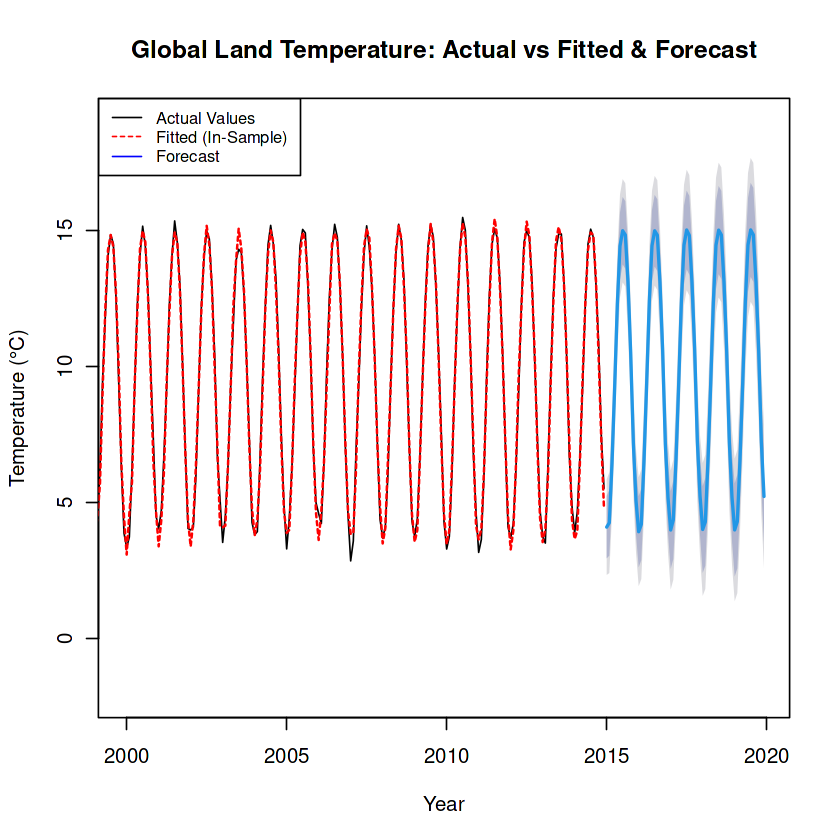

In [7]:
# Generate forecasts for the next 5 years (60 months)
forecast_result <- forecast(fit_arima, h = 60)

# Plot the time series (last 15 years + 5 year forecast)
plot(forecast_result, 
     xlim = c(max(time(temp_ts)) - 15, max(time(temp_ts)) + 5),
     main = "Global Land Temperature: Actual vs Fitted & Forecast",
     xlab = "Year",
     ylab = "Temperature (°C)")

# Plot the model's fitted (predicted) values for the historical period
lines(fitted(fit_arima), col = "red", lty = 2, lwd = 1.5)

# Add a legend to distinguish them
legend("topleft", 
       legend = c("Actual Values", "Fitted (In-Sample)", "Forecast"), 
       col = c("black", "red", "blue"), 
       lty = c(1, 2, 1), 
       cex = 0.8)


## Key Findings & Conclusion
* **Stationarity:** The series demonstrated stationarity in mean levels according to the ADF test, though seasonal differencing ($D=1$) was required to handle strong 12-month annual cycles.
* **Model Selected:** $\text{ARIMA}(2,0,2)(2,1,0)_{12}$ with drift effectively captured both short-term momentum and long-term upward warming trends.
* **Residual Diagnostic:** Low residual autocorrelation ($\text{ACF}_1 \approx 0.014$) confirms that the model successfully extracted predictable signals, leaving approximately white noise errors.
  